In [6]:
!pip install PyMPDATA

In [45]:
import numpy as np
import numba as nb
import matplotlib.pyplot as plt
from PyMPDATA import ScalarField, VectorField, Solver, Stepper, Options, boundary_conditions as bc
options = Options(n_iters=4, infinite_gauge=True, nonoscillatory=True, third_order_terms=True)

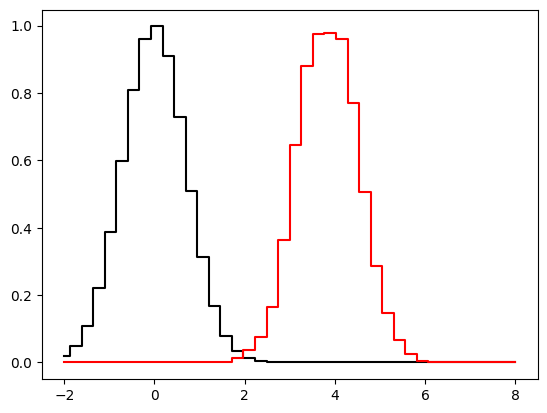

In [46]:
common = { 'halo': options.n_halo, 'boundary_conditions': (bc.Periodic(),) }

Psi = ScalarField(**common, data=np.exp(-(x := np.linspace(-2, 8, 40))**2))
C = VectorField(**common, data=(np.full(x.size + 1, .25),))

fig, ax = plt.subplots(1)

ax.step(x, Psi.get(), color='black', where='mid')

solver = Solver(advector=C, advectee=Psi, stepper=Stepper(n_dims=1, options=options))
solver.advance(60)

ax.step(x, Psi.get(), color='red', where='mid')
